# sub-16: recovering the bars sequence from the brain

3 bars runs of sub-16 (RightEye Bars01 and Bars02, LeftEye Bars01) are explained by no known stimulus (`sub16_stimulus_investigation_v2.ipynb`), although their signal is normal. Hypothesis: bars were shown, but in an order that is in none of our files (first, pilot session). Since the pRFs of sub-16 are well estimated by its rings and wedges, the bar shown at each TR can be estimated from the cortical response.

**Method**

1. **Dictionary of apertures**: bars of 4 orientations × 15 positions, with the width of the model's bars, inside the stimulated field; plus a blank screen.
2. **Score of each aperture at each TR**: correlation, across vertices, between the response at TR t + lag and the drive each aperture would produce, `(aperture · pRF)^n`, with the pRFs of the RingsWedges fit of the same eye.
3. **Smooth sequence**: Viterbi path through the apertures, with a penalty λ for any jump that is not a step of the bar (same orientation, neighbouring position) or a blank.
4. **Validation without circularity**: the sequence is estimated with the vertices of V1 + V3 and tested on V2 (and the reverse): the test vertices are not used to estimate it. Score = median correlation between the data of the test vertices and the prediction (canonical HRF, best delay).
5. **Controls of the method**: runs with a known stimulus — sub-13 (A), sub-17 (B), and BarsLeftEye run-02 of sub-16 (A). For them, the recovered sequence must look like the true one, and its test score must approach the score of the true stimulus.

**Reading**: if, for the suspect runs, the recovered sequence is a clean bar sequence and its test score is close to that of the good runs (~0.4-0.5), the shown stimulus is recovered and its design matrix can be used. Otherwise, no bars sequence explains these runs.

Read only. The recovered design matrices are saved in `Desktop/fig_od/sub16_recovered/` (not in the data folders). Run at the lab: about 5-15 min.

In [1]:
import os, glob, math
import numpy as np, pandas as pd, nibabel as nb
import scipy.io as sio
import matplotlib.pyplot as plt

main = '/Users/uriel/disks/meso_shared/amblyo7T_prf'
pp = f'{main}/derivatives/pp_data'
out_dir = '/Users/uriel/Desktop/fig_od/sub16_recovered'
os.makedirs(out_dir, exist_ok=True)
TR = 2.0
runs_to_do = [('sub-16', 'BarsLeftEye_run-01', 'suspect'), ('sub-16', 'BarsRightEye_run-01', 'suspect'),
              ('sub-16', 'BarsRightEye_run-02', 'suspect'), ('sub-16', 'BarsLeftEye_run-02', 'A'),
              ('sub-13', 'BarsLeftEye_run-01', 'A'), ('sub-13', 'BarsRightEye_run-01', 'A'),
              ('sub-17', 'BarsLeftEye_run-01', 'B'), ('sub-17', 'BarsRightEye_run-01', 'B')]
lam = 0.15          # penalty for a jump that is not a bar step (correlation units)
blank_score = 0.03  # score of the blank screen (a bar must do better to be chosen)
lags = [1, 2]       # response delay tested (TR)

/var/folders/60/q71xm4hx45x3db5d6mzl8r4h0000gn/T/ipykernel_4559/1242835645.py:2: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import numpy as np, pandas as pd, nibabel as nb


## Known stimuli and dictionary of bar apertures

In [2]:
def build_vdm(mat_fn):
    """Same conversion as create_vdm_files.ipynb (50 x 50, transposed, padded)."""
    im = np.asarray(sio.loadmat(mat_fn, squeeze_me=True, struct_as_record=False)['s'].im, float)
    out = np.zeros((50, 50, im.shape[-1]))
    ii = np.floor(np.arange(50) * 102 / 50).astype(int)
    for t in range(im.shape[-1]):
        f = (im[..., t] * 255).astype(np.uint8).T
        sq = np.vstack([np.zeros((12, 102), np.uint8), f, np.zeros((13, 102), np.uint8)])
        out[..., t] = (sq > 5)[np.ix_(ii, ii)]
    return out

model = np.load(f'{main}/derivatives/vdm/task-BarsBarsRingsWedgesLeftEye_vdm.npy')
A = model[..., :120]
B = build_vdm(f'{main}/sourcedata/C/jp/cond-1-stim-3.mat')
true_stim = {'A': A, 'B': B}
field = (model.max(-1) > 0) | (B.max(-1) > 0)                       # stimulated field
print('stimulated pixels:', field.sum(), '| rows', np.where(field.any(1))[0][[0, -1]], 'cols', np.where(field.any(0))[0][[0, -1]])

rr, cc = np.meshgrid(np.arange(50) - 24.5, np.arange(50) - 24.5, indexing='ij')
X_pix, Y_pix = cc, -rr                                               # pixel coordinates, y up

# bar width (pixels) from the model's bars: projected spread along the best orientation
thetas = np.deg2rad([0, 45, 90, 135])
widths = []
for t in range(120):
    m = A[..., t] > 0
    if m.sum() < 5: continue
    sds = [np.std(X_pix[m] * np.cos(th) + Y_pix[m] * np.sin(th)) for th in thetas]
    widths.append(min(sds) * np.sqrt(12))
w = float(np.median(widths))
print('bar width: {:.1f} pixels'.format(w))

cands, cand_info = [], []
for oi, th in enumerate(thetas):
    proj = X_pix * np.cos(th) + Y_pix * np.sin(th)
    dmax = np.abs(proj[field]).max()
    for pi, d in enumerate(np.linspace(-dmax + w / 2, dmax - w / 2, 15)):
        ap = ((np.abs(proj - d) <= w / 2) & field).astype(float)
        if ap.sum() > 0:
            cands.append(ap); cand_info.append((oi, pi))
cands.append(np.zeros((50, 50))); cand_info.append((-1, -1))         # blank
cands = np.array(cands)                                              # (n_cand, 50, 50)
cand_info = np.array(cand_info)
print(len(cands), 'apertures (incl. blank)')

# how well the dictionary describes the true stimuli (upper bound of the method)
def best_frame_match(stim):
    S = stim.reshape(-1, 120).T
    C = cands.reshape(len(cands), -1)
    num = S @ C.T
    den = np.sqrt((S ** 2).sum(1))[:, None] * np.sqrt((C ** 2).sum(1))[None] + 1e-9
    return np.where(S.sum(1) > 0, (num / den).max(1), np.nan)
for k, v in true_stim.items():
    print('{}: median overlap of each frame with its best dictionary bar = {:.2f}'.format(k, np.nanmedian(best_frame_match(v))))

stimulated pixels: 1903 | rows [ 4 43] cols [ 0 49]
bar width: 5.9 pixels
61 apertures (incl. blank)
A: median overlap of each frame with its best dictionary bar = 0.87
B: median overlap of each frame with its best dictionary bar = 0.87


## Data, ROIs and pRFs (RingsWedges fit)

In [3]:
cache = {}
def load_subject(s):
    if s in cache: return cache[s]
    roi = np.concatenate([nb.load(glob.glob(f'{pp}/{s}/fsnative/rois/{s}_hemi-{h}_fmriprep_dct_*_rois-group-mmp.func.gii')[0]).darrays[0].data
                          for h in ['L', 'R']])
    prf = {eye: np.hstack([np.vstack([a.data for a in nb.load(
        f'{pp}/{s}/fsnative/prfmodel/prf_derivatives/{s}_task-RingsWedges{eye}_hemi-{h}_fmriprep_dct_psc_concat_prf-css_deriv.func.gii').darrays])
        for h in ['L', 'R']]) for eye in ['LeftEye', 'RightEye']}
    cache[s] = (roi, prf)
    return cache[s]


def load_run(s, r):
    hs = []
    for h in ['L', 'R']:
        d = np.vstack([a.data for a in nb.load(
            f'{pp}/{s}/fsnative/func/fmriprep_dct_psc/{s}_ses-01_task-{r}_hemi-{h}_space-fsnative_fmriprep_dct_psc_bold.func.gii').darrays])
        hs.append(d if d.shape[0] == 120 else d.T)
    return np.hstack(hs)


pix = 2 * math.degrees(math.atan(50.6 / 2 / 242)) / 50                # current fits' convention
Xd, Yd = X_pix * pix, Y_pix * pix
t_ = np.arange(0, 32, TR)
g = lambda a: t_ ** (a - 1) * np.exp(-t_) / math.gamma(a)
H = g(6) - g(16) / 6; H /= H.sum()
N_fft = 256
Hf = np.fft.rfft(H, n=N_fft)


def conv_hrf(d):
    return np.fft.irfft(np.fft.rfft(d, n=N_fft, axis=0) * Hf[:, None], n=N_fft, axis=0)[:d.shape[0]]


def zc(a, axis=0):
    a = a - a.mean(axis, keepdims=True)
    return a / (a.std(axis, keepdims=True) + 1e-9)


def drive(stim_frames, x0, y0, s, n):
    """(frames, 50, 50) -> (frames, vertices)."""
    G = np.exp(-((Xd.ravel()[:, None] - x0) ** 2 + (Yd.ravel()[:, None] - y0) ** 2) / (2 * s ** 2))
    return np.clip(stim_frames.reshape(len(stim_frames), -1) @ G, 0, None) ** n

## Estimation (scores + Viterbi) and cross-validated test

In [4]:
# transition penalties: 0 = stay, bar step (same orientation, neighbouring position), to/from blank; lam otherwise
nc = len(cands)
P = np.full((nc, nc), lam)
for i in range(nc):
    for j in range(nc):
        oi, pi = cand_info[i]; oj, pj = cand_info[j]
        if i == j or oi == -1 or oj == -1 or (oi == oj and abs(pi - pj) <= 1):
            P[i, j] = 0.0


def viterbi(E):
    """E: (T, n_cand) scores -> best path maximising sum(E) - penalties."""
    T = len(E)
    V = E[0].copy(); back = np.zeros((T, nc), int)
    for t in range(1, T):
        M = V[:, None] - P                       # prev x next
        back[t] = M.argmax(0)
        V = M.max(0) + E[t]
    path = [int(V.argmax())]
    for t in range(T - 1, 0, -1):
        path.append(back[t][path[-1]])
    return np.array(path[::-1])


def estimate(y, D_est, lag):
    """y: (120, n_vert) data of the estimation vertices; D_est: pRF parameters -> sequence of apertures (120, 50, 50)."""
    x0, y0, s, n = D_est
    Dc = drive(cands, x0, y0, s, n)              # (n_cand, n_vert)
    Dz = zc(Dc, axis=1); Dz[-1] = 0              # blank: no spatial pattern
    Y = zc(y, axis=0)
    Y = np.vstack([Y[lag:], np.zeros((lag, Y.shape[1]))])
    Yz = zc(Y, axis=1)                           # spatial pattern at each TR
    E = Yz @ Dz.T / Y.shape[1]                   # (120, n_cand) spatial correlations
    E[:, -1] = blank_score
    E[-lag:] = 0
    path = viterbi(E)
    return cands[path], path, E


def test_score(stim, y, D_test):
    """Median correlation between data and prediction of the test vertices, best delay among -2..+2 TR."""
    x0, y0, s, n = D_test
    p = conv_hrf(drive(np.moveaxis(stim, -1, 0) if stim.shape[0] == 50 else stim, x0, y0, s, n))
    best = -np.inf
    for sh in range(-2, 3):
        q = np.roll(p, sh, 0)
        if sh > 0: q[:sh] = p[0]
        elif sh < 0: q[sh:] = p[-1]
        best = max(best, float(np.median((zc(q) * zc(y)).mean(0))))
    return best


rows, recovered = [], {}
for s, r, kind in runs_to_do:
    roi, prf = load_subject(s)
    eye = 'LeftEye' if 'LeftEye' in r else 'RightEye'
    D = prf[eye]
    y_all = load_run(s, r)
    ok = (D[0] > 0.2) & (D[1] < 6) & np.isfinite(y_all).all(0) & (y_all.std(0) > 0)
    sets = {'V1V3': np.where(ok & ((roi == 1) | (roi == 3)))[0], 'V2': np.where(ok & (roi == 2))[0]}
    par = lambda idx: (D[7][idx], D[8][idx], np.clip(D[4][idx], 0.2, None), np.clip(D[11][idx], 0.05, 1))
    res = {'subject': s, 'run': r, 'true stimulus': kind}
    best = None
    for lag in lags:
        sc = []
        for est_set, test_set in [('V1V3', 'V2'), ('V2', 'V1V3')]:
            seq, _, _ = estimate(y_all[:, sets[est_set]], par(sets[est_set]), lag)
            sc.append(test_score(seq, y_all[:, sets[test_set]], par(sets[test_set])))
        res[f'cv r recovered (lag {lag})'] = np.mean(sc)
        if best is None or np.mean(sc) > best[0]: best = (np.mean(sc), lag)
    lag = best[1]
    all_idx = np.where(ok & (roi >= 1) & (roi <= 3))[0]
    seq, path, E = estimate(y_all[:, all_idx], par(all_idx), lag)
    recovered[(s, r)] = (seq, path, lag)
    np.save(f'{out_dir}/{s}_{r}_recovered_vdm.npy', np.moveaxis(seq, 0, -1))
    # reference scores on the same split with the known stimuli
    for k, v in true_stim.items():
        res[f'cv r true {k}'] = np.mean([test_score(v, y_all[:, sets[t]], par(sets[t])) for t in ['V2', 'V1V3']])
        rec = np.moveaxis(seq, 0, -1)
        res[f'frame corr recovered vs {k}'] = np.corrcoef(rec.ravel(), v.ravel())[0, 1]
    res['best lag'] = lag
    res['n_bars'] = int((path != nc - 1).sum())
    res['n_jumps'] = int(sum(P[path[t - 1], path[t]] > 0 for t in range(1, 120)))
    rows.append(res)
    print(s, r, 'done', flush=True)
rec_tab = pd.DataFrame(rows).set_index(['subject', 'run'])
rec_tab.round(3)

sub-16 BarsLeftEye_run-01 done
sub-16 BarsRightEye_run-01 done
sub-16 BarsRightEye_run-02 done
sub-16 BarsLeftEye_run-02 done
sub-13 BarsLeftEye_run-01 done
sub-13 BarsRightEye_run-01 done
sub-17 BarsLeftEye_run-01 done
sub-17 BarsRightEye_run-01 done


true stimulus  cv r recovered (lag 1)  \
subject run                                                         
sub-16  BarsLeftEye_run-01        suspect                   0.213   
        BarsRightEye_run-01       suspect                   0.216   
        BarsRightEye_run-02       suspect                   0.177   
        BarsLeftEye_run-02              A                   0.208   
sub-13  BarsLeftEye_run-01              A                   0.370   
        BarsRightEye_run-01             A                   0.315   
sub-17  BarsLeftEye_run-01              B                   0.317   
        BarsRightEye_run-01             B                   0.296   

                             cv r recovered (lag 2)  cv r true A  \
subject run                                                        
sub-16  BarsLeftEye_run-01                    0.214        0.146   
        BarsRightEye_run-01                   0.218        0.040   
        BarsRightEye_run-02                   0.182        0.042   
        BarsLeftEye_run-02                    0.213        0.454   
sub-13  BarsLeftEye_run-01                    0.373        0.433   
        BarsRightEye_run-01                   0.314        0.566   
sub-17  BarsLeftEye_run-01                    0.315        0.200   
        BarsRightEye_run-01                   0.304        0.161   

                             frame corr recovered vs A  cv r true B  \
subject run                                                           
sub-16  BarsLeftEye_run-01                       0.016        0.055   
        BarsRightEye_run-01                      0.016        0.003   
        BarsRightEye_run-02                      0.092        0.021   
        BarsLeftEye_run-02                       0.328        0.155   
sub-13  BarsLeftEye_run-01                       0.421        0.092   
        BarsRightEye_run-01                      0.261        0.213   
sub-17  BarsLeftEye_run-01                       0.050        0.564   
        BarsRightEye_run-01                      0.062        0.531   

                             frame corr recovered vs B  best lag  n_bars  \
subject run                                                                
sub-16  BarsLeftEye_run-01                       0.037         2      81   
        BarsRightEye_run-01                     -0.015         2      76   
        BarsRightEye_run-02                      0.020         2      75   
        BarsLeftEye_run-02                       0.073         2      81   
sub-13  BarsLeftEye_run-01                       0.092         2     100   
        BarsRightEye_run-01                      0.110         1      84   
sub-17  BarsLeftEye_run-01                       0.299         1      78   
        BarsRightEye_run-01                      0.417         2      84   

                             n_jumps  
subject run                           
sub-16  BarsLeftEye_run-01         0  
        BarsRightEye_run-01        2  
        BarsRightEye_run-02        0  
        BarsLeftEye_run-02         1  
sub-13  BarsLeftEye_run-01         2  
        BarsRightEye_run-01        4  
sub-17  BarsLeftEye_run-01         4  
        BarsRightEye_run-01        3

### Recovered sequences

Frames every 8 s: true A and B on top, then the recovered sequence of each run (white = bar).

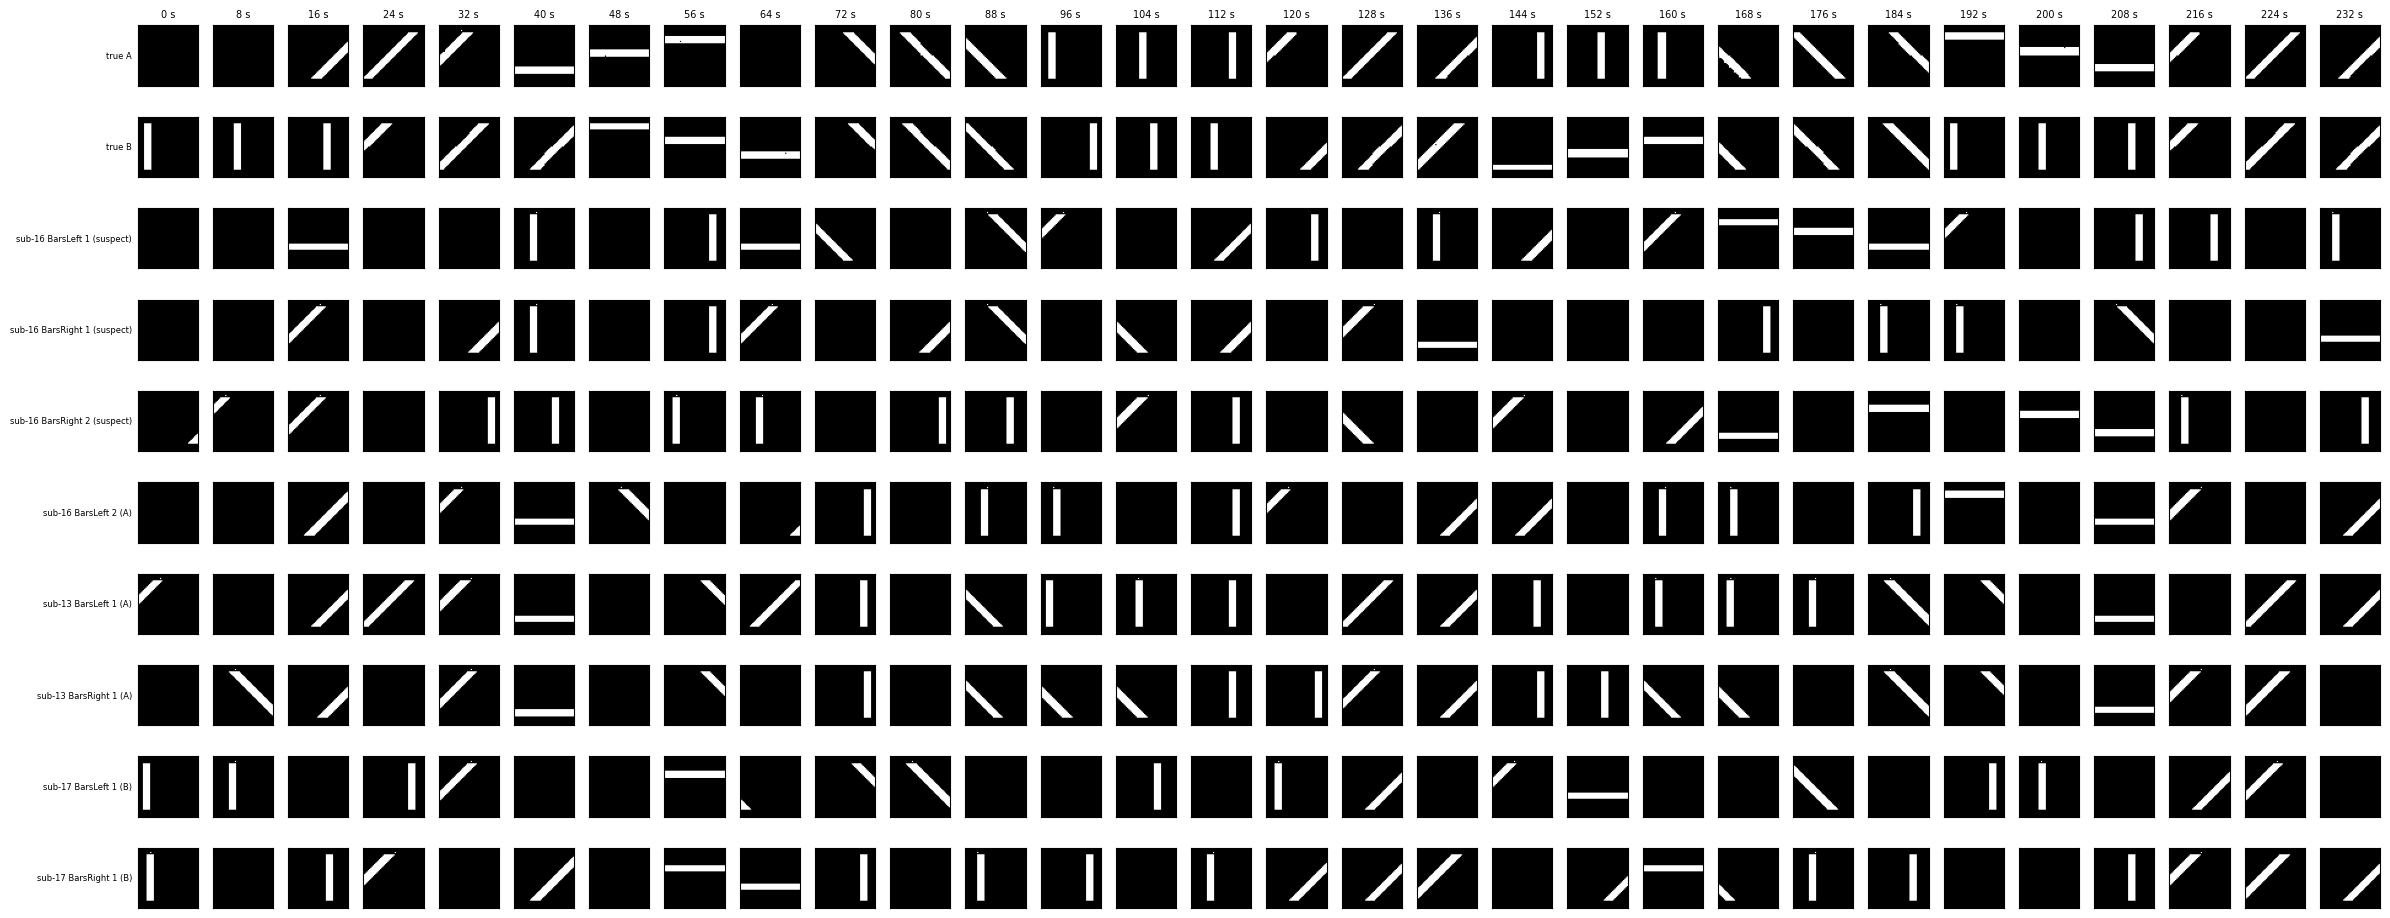

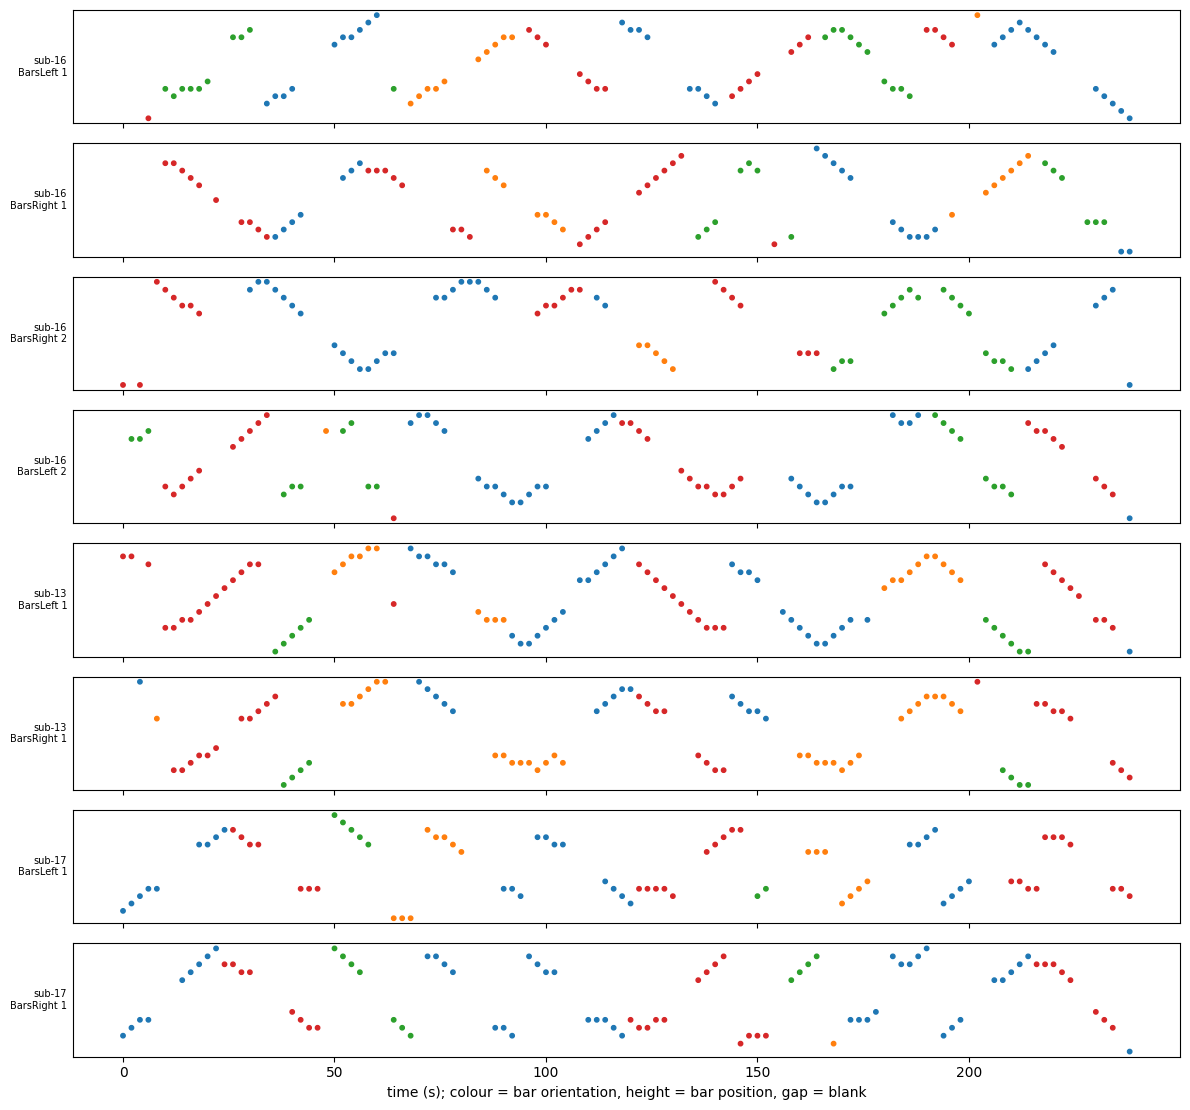

In [5]:
frames = list(range(0, 120, 4))
show = [('true A', np.moveaxis(A, -1, 0)), ('true B', np.moveaxis(B, -1, 0))] + \
       [('{} {} ({})'.format(s, r.replace('Eye_run-0', ' '), k), recovered[(s, r)][0]) for s, r, k in runs_to_do]
fig, axes = plt.subplots(len(show), len(frames), figsize=(len(frames) * 0.8, len(show) * 0.95))
for i, (name, mov) in enumerate(show):
    for j, t in enumerate(frames):
        axes[i, j].imshow(mov[t], cmap='gray', vmin=0, vmax=1)
        axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
        if i == 0: axes[i, j].set_title('{} s'.format(int(t * TR)), fontsize=7)
    axes[i, 0].set_ylabel(name, fontsize=6, rotation=0, ha='right', va='center')
plt.tight_layout()
fig.savefig('/Users/uriel/Desktop/fig_od/sub16_recovered_sequences.pdf', bbox_inches='tight')
plt.show()

# orientation / position of the bar over time (easier to read than frames)
fig, axes = plt.subplots(len(runs_to_do), 1, figsize=(12, 1.4 * len(runs_to_do)), sharex=True)
for ax, (s, r, k) in zip(axes, runs_to_do):
    path = recovered[(s, r)][1]
    o, p = cand_info[path, 0], cand_info[path, 1]
    ax.scatter(np.arange(120)[o >= 0] * TR, p[o >= 0], c=o[o >= 0], cmap='tab10', vmin=0, vmax=9, s=10)
    ax.set_ylabel('{}\n{}'.format(s, r.replace('Eye_run-0', ' ')), fontsize=7, rotation=0, ha='right', va='center')
    ax.set_yticks([])
axes[-1].set_xlabel('time (s); colour = bar orientation, height = bar position, gap = blank')
plt.tight_layout()
fig.savefig('/Users/uriel/Desktop/fig_od/sub16_recovered_paths.pdf', bbox_inches='tight')
plt.show()

## Decision

In [6]:
t = rec_tab.copy()
t['cv r recovered'] = t[[c_ for c_ in t.columns if c_.startswith('cv r recovered')]].max(axis=1)
t['cv r true (matching)'] = [row['cv r true A'] if row['true stimulus'] == 'A' else row['cv r true B'] if row['true stimulus'] == 'B' else np.nan
                             for _, row in t.iterrows()]
print(t[['true stimulus', 'cv r recovered', 'cv r true (matching)', 'cv r true A', 'cv r true B',
         'frame corr recovered vs A', 'frame corr recovered vs B', 'best lag', 'n_bars', 'n_jumps']].round(3).to_string())
ctrl = t[t['true stimulus'] != 'suspect']
print('\nControls: recovered / true cross-validated r = {:.2f} (median). The method works if the recovered sequence of the controls'
      ' reaches most of the true stimulus score and looks like it (frame corr).'.format((ctrl['cv r recovered'] / ctrl['cv r true (matching)']).median()))
print('Suspect runs: if their cross-validated r reaches the level of the controls (recovered), use the recovered design matrix '
      '(saved in {}); otherwise no bars sequence explains them.'.format(out_dir))

                            true stimulus  cv r recovered  cv r true (matching)  cv r true A  cv r true B  frame corr recovered vs A  frame corr recovered vs B  best lag  n_bars  n_jumps
subject run                                                                                                                                                                               
sub-16  BarsLeftEye_run-01        suspect           0.214                   NaN        0.146        0.055                      0.016                      0.037         2      81        0
        BarsRightEye_run-01       suspect           0.218                   NaN        0.040        0.003                      0.016                     -0.015         2      76        2
        BarsRightEye_run-02       suspect           0.182                   NaN        0.042        0.021                      0.092                      0.020         2      75        0
        BarsLeftEye_run-02              A           0.213        